In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

Ahora necesitamos precios o valuaciones de un activo que sean reales para calcular retornos y posteriormente aplicar todo lo de montecarlo que ya vimos, sin embargo, al mencionar esto nace algo interesante dentro de la misma oración "de un activo", será posible simular y hacer inferencias pero de varios activos al mismo tiempo?, considerando que podrían estar relacionados?. Pues trataremos de explicarlo después c:
Hagamos el cálculo de retorno y volatilidad a través del activo financiero SPY: SPY es el símbolo bursátil del SPDR S&P 500 ETF Trust, el primer y más grande fondo cotizado en bolsa (ETF) de EE. UU. diseñado para replicar el rendimiento del índice S&P 500. Permite invertir en las 500 empresas más grandes de EE. UU. (como Apple, Amazon, Microsoft) comprando un solo activo, ofreciendo alta liquidez y diversificación.

In [2]:
ticker = "SPY" #nombre del activo 
datos = yf.download(ticker, start="2015-01-01", end="2026-01-01", progress=False)
print(datos.head())
print(datos.tail())


Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2015-01-02  170.125000  171.325815  169.089824  170.911744  121465900
2015-01-05  167.052628  169.247196  166.746219  169.081571  169632600
2015-01-06  165.479187  167.880792  164.684166  167.359059  209151400
2015-01-07  167.541214  167.880755  166.356978  166.804169  125346700
2015-01-08  170.514221  170.729546  168.932482  168.949035  147217800
Price            Close        High         Low        Open    Volume
Ticker             SPY         SPY         SPY         SPY       SPY
Date                                                                
2025-12-24  688.499695  688.948481  685.926705  686.076320  39445600
2025-12-26  688.429871  689.776169  687.392725  688.758989  41613300
2025-12-29  685.976562  687.322922  684.201442  685.667409  62559500
2025-12-30  685.138916  68

In [3]:
#Calculamos los retornos
retornos = datos["Close"].pct_change()

retornos = retornos.dropna()

print(retornos.head())
print(retornos.tail())

Ticker           SPY
Date                
2015-01-05 -0.018059
2015-01-06 -0.009419
2015-01-07  0.012461
2015-01-08  0.017745
2015-01-09 -0.008014
Ticker           SPY
Date                
2025-12-24  0.003518
2025-12-26 -0.000101
2025-12-29 -0.003564
2025-12-30 -0.001221
2025-12-31 -0.007409


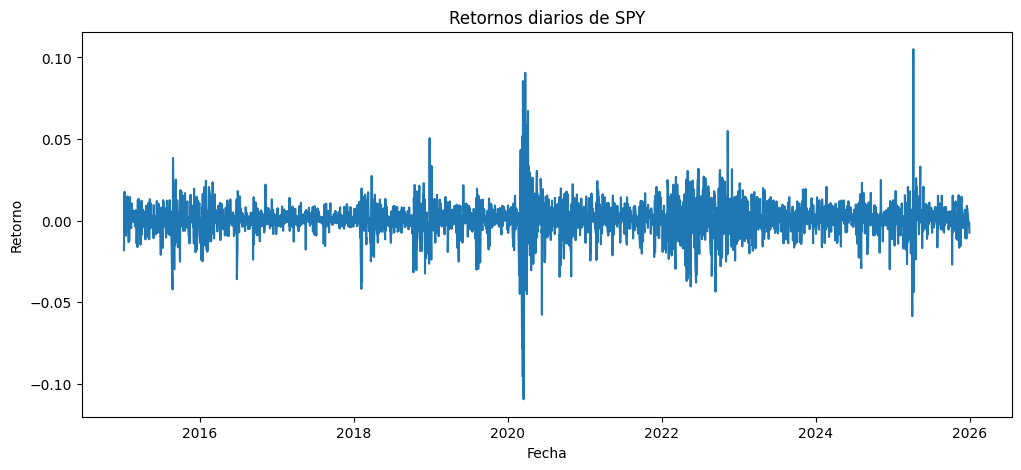

In [4]:
# Graficamos los retornos
plt.figure(figsize=(12,5))

plt.plot(retornos)

plt.title("Retornos diarios de SPY")
plt.xlabel("Fecha")
plt.ylabel("Retorno")

plt.show()

Podemos observar que en general parece aleatorios los retornos, sin embargo, hay algunos sucesos que son dependientes de situaciones específicas tales como la PANDEMIA en 2021 o la toma de presidencia de Donal Trump en 2025, esto influencia y mueve este tipo de activos, por lo que podrían ser considerados outliers y proceder a alguna imputacion de datos, tomar ventanas de tiempo más pequeñas para un mejor análisis. 

In [5]:
mu_d = retornos.mean()
sigma_d = retornos.std()

print("Media diaria:", mu_d)
print("Volatilidad diaria:", sigma_d)

Media diaria: Ticker
SPY    0.000564
dtype: float64
Volatilidad diaria: Ticker
SPY    0.011208
dtype: float64


Así la media histórica diaria es de 0.0005 y la volatilidad diaria de 0.011208, sin embargo considerar 11 años de história y con los datos que hablamos (Pandemia y Trump) son influyentes en dichos resultados, por ello mejor sólo tomemos 3 años

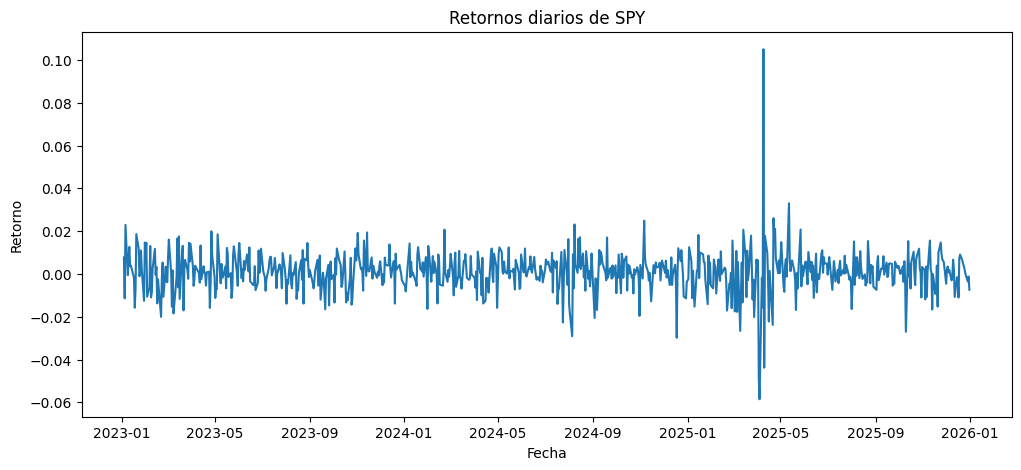

In [6]:
datos = yf.download(ticker, start="2023-01-01", end="2026-01-01", progress=False)
retornos = datos["Close"].pct_change()
retornos = retornos.dropna()

# Graficamos los retornos
plt.figure(figsize=(12,5))

plt.plot(retornos)

plt.title("Retornos diarios de SPY")
plt.xlabel("Fecha")
plt.ylabel("Retorno")

plt.show()


In [7]:
mu_d = retornos.mean().values[0]
sigma_d = retornos.std().values[0]

print("Media diaria:", mu_d)
print("Volatilidad diaria:", sigma_d)

Media diaria: 0.000875121069998025
Volatilidad diaria: 0.00967001890002027


Así se tienen retornos esperados de 0.000875 y volatilidad de 0.00967, menores pero también más estables lo que nos da una intuición que podría arrojar estimaciones más precisas.

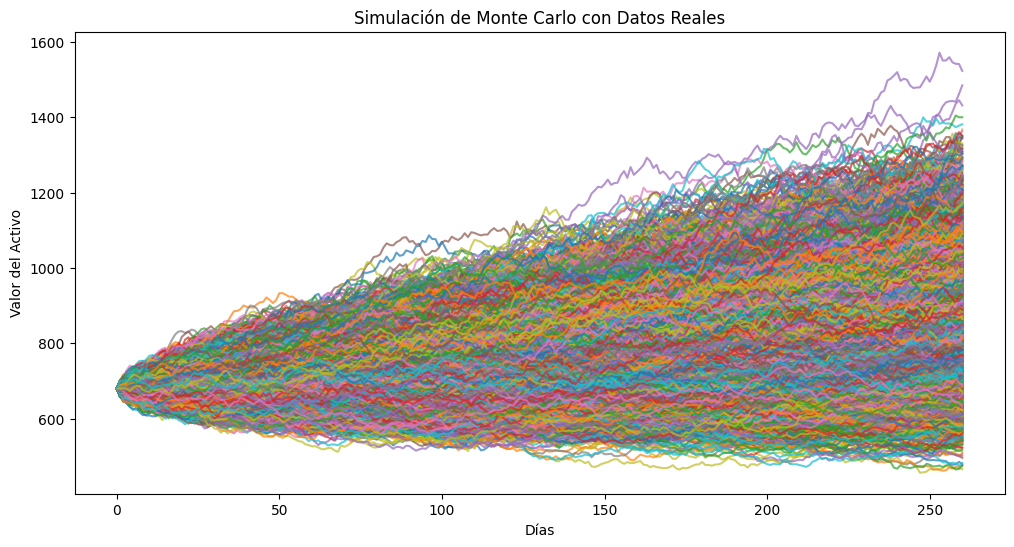

In [8]:
#Así podemos ahora calcular una simulación de 5*52 días
capini = datos["Close"].values[-1][0]
dias = 52*5
np.random.seed(123)
simulaciones = 10000

#Creamos la figura
plt.figure(figsize=(12,6))

ultimos_valores = []
dia_siguiente = []
for _ in range(simulaciones):
    retornos=np.random.normal(mu_d, sigma_d, dias)
    trayectoria = [capini]

    for r in retornos:
        nuevo_valor = trayectoria[-1]*(1+r)
        trayectoria.append(nuevo_valor)
    plt.plot(trayectoria, alpha = 0.7) #El alpha hace líneas transparentes para mejorar la visibilidad
    ultimos_valores.append(trayectoria[-1])
    dia_siguiente.append(trayectoria[1])

plt.title("Simulación de Monte Carlo con Datos Reales")
plt.xlabel("Días")
plt.ylabel("Valor del Activo")

plt.show()

In [9]:
#Así la distribución de valores finales (precio al final del año) es:
ultimos_valores = np.array(ultimos_valores)

#Estadísticas
promedio = np.mean(ultimos_valores)
mediana = np.median(ultimos_valores)

percentil_5 = np.percentile(ultimos_valores, 5)
percentil_95 = np.percentile(ultimos_valores, 95)

# Probabilidad de Pérdida
prob_perdida = np.mean(ultimos_valores < capini)

print(f"Promedio final: $ {promedio:,.2f}")
print(f"Mediana final: $ {mediana:,.2f}")

print(f"Percentil 5 (VaR 95): $ {percentil_5:,.2f}")
print(f"Percentil 95: $ {percentil_95:,.2f}")

print(f"Probabilidad de perder: {prob_perdida:,.2f}")


Promedio final: $ 854.18
Mediana final: $ 844.95
Percentil 5 (VaR 95): $ 650.54
Percentil 95: $ 1,093.24
Probabilidad de perder: 0.09


<function matplotlib.pyplot.show(close=None, block=None)>

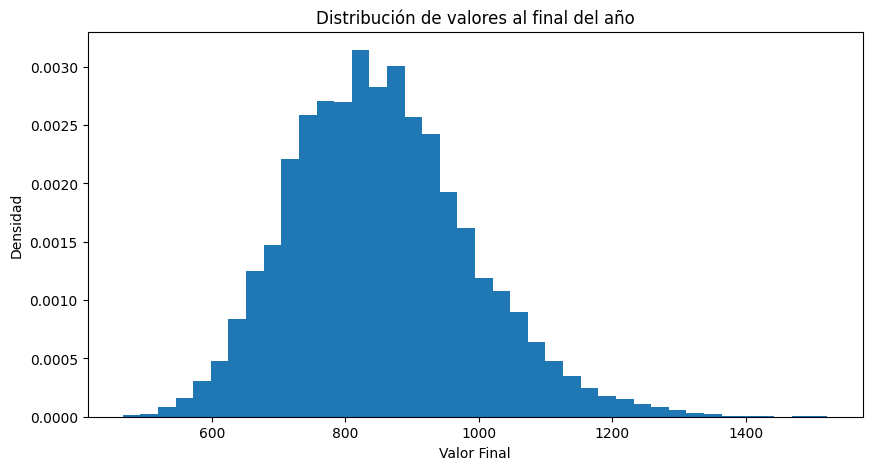

In [10]:
plt.figure(figsize=(10,5))

plt.hist(ultimos_valores, bins=40, density=True)

plt.title("Distribución de valores al final del año")
plt.xlabel("Valor Final")
plt.ylabel("Densidad")

plt.show

Sin embargo, algo más inmediato sería la distribución de los precios al día siguiente, que como podemos ver en el siguiente código es:

In [11]:
#Así la distribución de valores finales (precio al final del dia siguiente) es:

dia_siguiente = np.array(dia_siguiente)

#Estadísticas
promedio = np.mean(dia_siguiente)
mediana = np.median(dia_siguiente)

percentil_5 = np.percentile(dia_siguiente, 5)
percentil_95 = np.percentile(dia_siguiente, 95)

# Probabilidad de Pérdida
prob_perdida = np.mean(dia_siguiente < capini)

precio_final_real = yf.download(ticker, start="2026-01-02", end="2026-01-03", progress=False)["Close"].values[0][0]

print(f"Precio Inicial Real: $ {capini:,.2f}" )
print(f"Precio Final Real: $ {precio_final_real:,.2f}" )
print(f"Promedio final: $ {promedio:,.2f}")
print(f"Mediana final: $ {mediana:,.2f}")

print(f"Percentil 5 (VaR 95): $ {percentil_5:,.2f}")
print(f"Percentil 95: $ {percentil_95:,.2f}")

print(f"Probabilidad de perder: {prob_perdida:,.2f}")





Precio Inicial Real: $ 680.06
Precio Final Real: $ 681.31
Promedio final: $ 680.69
Mediana final: $ 680.66
Percentil 5 (VaR 95): $ 669.84
Percentil 95: $ 691.54
Probabilidad de perder: 0.46


<function matplotlib.pyplot.show(close=None, block=None)>

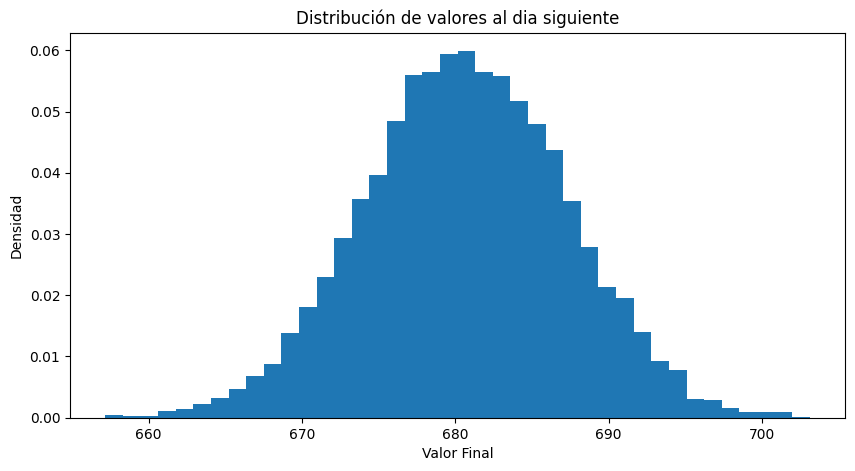

In [12]:
plt.figure(figsize=(10,5))

plt.hist(dia_siguiente, bins=40, density=True)

plt.title("Distribución de valores al dia siguiente")
plt.xlabel("Valor Final")
plt.ylabel("Densidad")

plt.show

Sin embargo esta forma de simulación responde a algo básico de como se cree que funciona las inversiones, hagamos una pequeña comparación a nivel anual con otro modelo muy famoso en el ámbito financiero, el Browniano Geométrico, en particular su simulación, la cual se sigue de la fórmula:

$$S_t = S_0 \exp{((\mu - \dfrac{1}{2}\sigma^2)t+\sigma \sqrt{t}Z)}$$

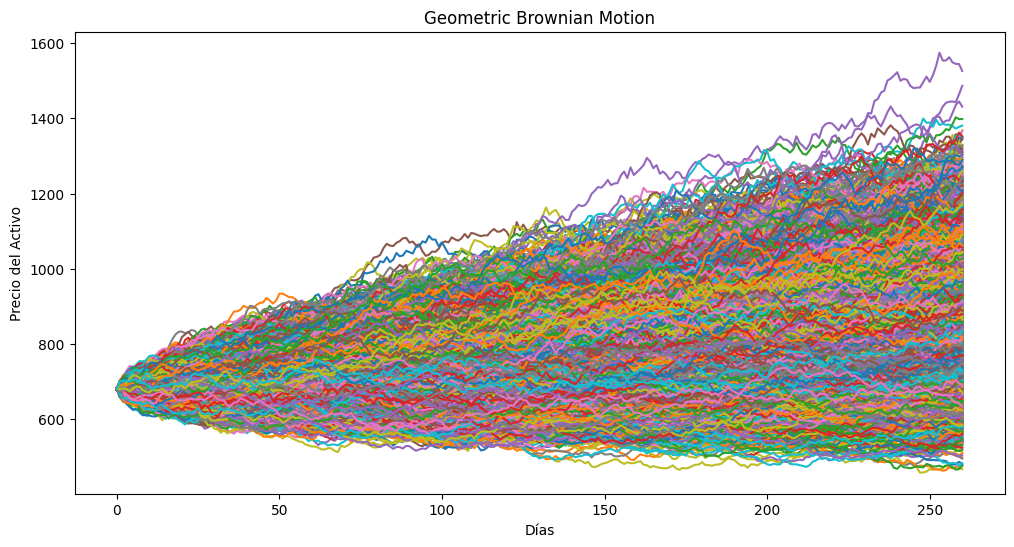

In [13]:
np.random.seed(123)
So = capini #Precio del activo inicial
#Utilizaremos mu_d y sigma_d calculadas anteriormente

Tr = 1

dt = Tr/dias

simulaciones = 10000

mu = dias*mu_d
sigma = np.sqrt(dias)*sigma_d

ultimos_valores = []
dia_siguiente = []

plt.figure(figsize=(12,6))

for _ in range(simulaciones):
    precios = [So]

    for t in range(dias):
        Z = np.random.normal()
        St = precios[-1]*np.exp((mu-0.5*sigma**2)*dt+sigma*np.sqrt(dt)*Z)
        precios.append(St)
    plt.plot(precios)
    ultimos_valores.append(precios[-1])
    dia_siguiente.append(precios[1])

plt.title("Geometric Brownian Motion")
plt.xlabel("Días")
plt.ylabel("Precio del Activo")

plt.show()


In [14]:
#Así la distribución de valores finales (precio al final del dia siguiente) es:

dia_siguiente = np.array(dia_siguiente)

#Estadísticas
promedio = np.mean(dia_siguiente)
mediana = np.median(dia_siguiente)

percentil_5 = np.percentile(dia_siguiente, 5)
percentil_95 = np.percentile(dia_siguiente, 95)

# Probabilidad de Pérdida
prob_perdida = np.mean(dia_siguiente < capini)

precio_final_real = yf.download(ticker, start="2026-01-02", end="2026-01-03", progress=False)["Close"].values[0][0]

print(f"Precio Inicial Real: $ {capini:,.2f}" )
print(f"Precio Final Real: $ {precio_final_real:,.2f}" )
print(f"Promedio final: $ {promedio:,.2f}")
print(f"Mediana final: $ {mediana:,.2f}")

print(f"Percentil 5 (VaR 95): $ {percentil_5:,.2f}")
print(f"Percentil 95: $ {percentil_95:,.2f}")

print(f"Probabilidad de perder: {prob_perdida:,.2f}")

Precio Inicial Real: $ 680.06
Precio Final Real: $ 681.31
Promedio final: $ 680.69
Mediana final: $ 680.63
Percentil 5 (VaR 95): $ 669.88
Percentil 95: $ 691.61
Probabilidad de perder: 0.47


Podemos darnos cuenta que ambos modelos tienen muchísima similitud, sin embargo sus principales diferencias son el tiempo que tardan (Browniano tarda casi el doble), sin embargo, el Browniano en este caso tuvó mejor precisión estrechando las estimaciones. 

---

Un paso adicional que podemos realizar es hacer una validación de que tan bien funciona la simulación y la predicción, lo haremos con el ticket SPY que lo usaremos constantemento a lo largo de todos estas Notebooks. 

In [91]:
# =========================================
# 1. DESCARGAR DATOS
# =========================================
datos = yf.download(
    "BTC-USD",
    start="2018-01-01",
    progress=False
)["Close"]

# Eliminar faltantes
datos = datos.dropna()
# =========================================
# 2. DEFINIR VENTANAS
# =========================================

# Datos a calibrar
train = datos.loc[:'2019-12-31']

# 6 meses reales posteriores
test = datos.loc['2020-01-01':'2020-12-31']

retornos = train.pct_change().dropna()

# Media vectorial
mu = retornos.mean().values
sd = retornos.std().values


# =========================================
# 4. PARÁMETROS DE SIMULACIÓN
# =========================================

dias = len(test)

simulaciones = 50

# Precios iniciales
S0 = float(datos.loc[:'2019-12-31'].iloc[-1])

C:\Users\emili\AppData\Local\Temp\ipykernel_8736\993117240.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  S0 = float(datos.loc[:'2019-12-31'].iloc[-1])


In [94]:
# =========================================
# 5. MONTE CARLO
# =========================================

simulaciones_spy = []
np.random.seed(123)

for _ in range(simulaciones):

    precios = np.zeros((dias + 1, 2))

    precios[0] = S0

    for t in range(1, dias + 1):

        # Shocks
        Z = np.random.normal(mu, sd)

        # Evolución GBM discreta
        precios[t] = precios[t - 1] * (1 + Z)

    simulaciones_spy.append(precios[:,0])



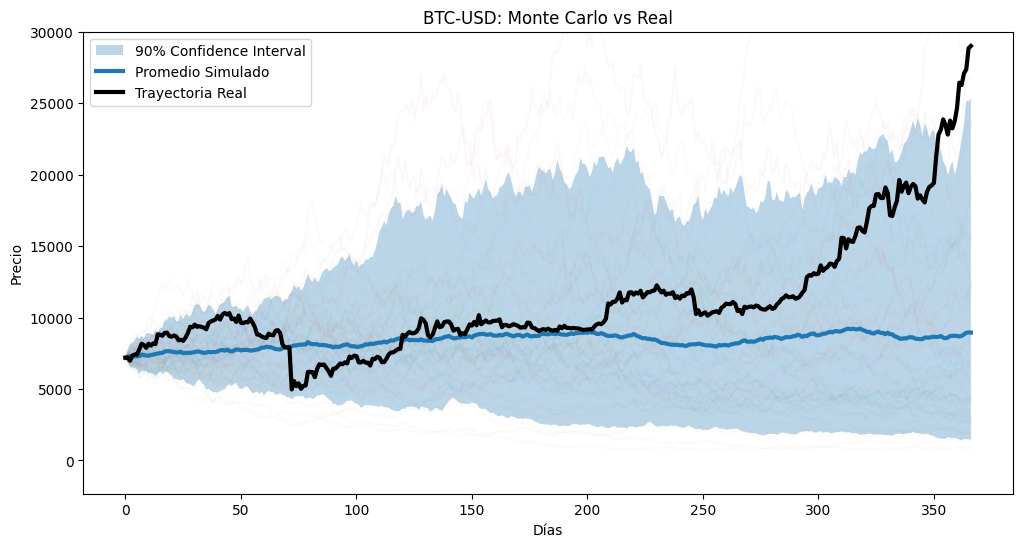

In [100]:
# =========================================
# 6. GRAFICAR BTC
# =========================================

# Convertir simulaciones a array
sim_spy_array = np.array(simulaciones_spy)

# Promedio diario
promedio_spy = sim_spy_array.mean(axis=0)

# Intervalos de confianza
p5 = np.percentile(sim_spy_array, 5, axis=0)
p95 = np.percentile(sim_spy_array, 95, axis=0)

# Trayectoria real
real_spy = np.concatenate([[S0], test["BTC-USD"].values])

# Eje temporal
x = np.arange(dias + 1)

# Graficar
plt.figure(figsize=(12,6))

# Banda de confianza
plt.fill_between(
    x,
    p5,
    p95,
    alpha=0.3,
    label="90% Confidence Interval"
)

# Simulaciones individuales
for sim in simulaciones_spy:
    plt.plot(sim, alpha=0.03)

# Trayectoria promedio
plt.plot(
    promedio_spy,
    linewidth=3,
    label="Promedio Simulado"
)

# Trayectoria real
plt.plot(
    real_spy,
    color="black",
    linewidth=3,
    label="Trayectoria Real"
)

plt.title("BTC-USD: Monte Carlo vs Real")

plt.xlabel("Días")
plt.ylabel("Precio")
plt.ylim(top=30000)

plt.legend()

plt.show()